# USD/EUR forecasting with XGBOOST

Standalone adaptation of the matching `BTC_TEST` notebook and the `time-series-forecasting` skill. Source: `CSV/USD_EUR_Historical.csv`; target: `Price`; units: **EUR per USD**.

**Flow:** source audit → raw chronological 80/20 Train/Test (no validation) → descriptive EDA → Train-only development and diagnostics → frozen rolling-origin Test forecasts → separate latest-origin future forecasts → RMSE/MAPE by horizon → plots and execution-generated summary.

**Asset adaptation declared before Test:** horizons [1, 5, 10, 20] count successive **observations**, not calendar days or a guaranteed month. Window models use 40 observed returns (roughly eight 5-day weeks, or fewer weeks for the WTI source). No artificial weekend/holiday prices. The supplied CSV has no exchange-calendar metadata; missing dates are disclosed. Future dates are projected from a declared weekday pattern and are not confirmed exchange sessions.

Run all cells from a fresh **Python 3.12 (vs_nine TensorFlow)** kernel using `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`. Versions and actual executable are printed and saved. Output: `OUTPUT/XGBOOST_USD/{tables,figures,summaries,models}`.

Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.

**Horizon update:** `[1, 3, 5, 7, 14, 21, 30]` observed steps, as explicitly requested by the user. Previous cell outputs were cleared. Restart the kernel and run all cells to regenerate models, forecasts, metrics and exported results for this configuration; existing files in OUTPUT still belong to the previous execution until rerun.


## 1. Imports and environment

In [1]:
from pathlib import Path
import os, sys, json, random, hashlib, warnings, time
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import joblib
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display, Markdown, HTML

from xgboost import XGBRegressor

## 2. Single configuration cell
All experiment settings are declared before Test inference. These are reference-informed fixed settings, not claimed asset-specific optima. Change them only as a new, explicitly documented experiment after viewing Test.

In [2]:
ASSET = 'USD'
ASSET_NAME = 'USD/EUR'
MODEL = 'XGBOOST'
UNIT = 'EUR per USD'
ASSET_NOTE = 'Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.'
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CSV' / 'USD_EUR_Historical.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Start Jupyter in PROJECT_2026 or the asset notebook folder.')
DATA_PATH = PROJECT_ROOT / 'CSV' / 'USD_EUR_Historical.csv'
DATE_COL, TARGET_COL, DATE_FORMAT = 'Date', 'Price', '%m/%d/%Y'
TRAIN_RATIO = 0.8
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
LOOKBACK = 40
TRANSFORMATION = 'log price for ARIMA; observed-step log returns for feature/MIMO models'
WEEKMASK = 'Mon Tue Wed Thu Fri'
CALENDAR_NOTE = 'Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.'
CALENDAR_POLICY_USER_ACKNOWLEDGED = False
SEEDS = [0]
ALPHA = 0.05
DIAGNOSTIC_LAGS = [10,20,30]
ROLLING_WINDOW = 20
SETTINGS = {'objective': 'reg:squarederror', 'n_estimators': 100, 'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 1, 'gamma': 0, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'tree_method': 'hist', 'random_state': 0, 'n_jobs': 2}
PACKAGES = ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'scikit-learn', 'joblib', 'xgboost']
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)

# Separate PI models; original point-forecast settings are unchanged.
XGB_PI_ALPHA = 0.05
XGB_PI_QUANTILES = [XGB_PI_ALPHA/2, 1-XGB_PI_ALPHA/2]


## 3. Output helpers, provenance and diagnostics
Process checks enforce chronology, leakage prevention and frozen fitted state. Statistical diagnostics with no declared selection threshold are marked **REPORTED**. No statistical test on Test controls tuning or refitting.

In [3]:
assert HORIZONS == sorted(set(HORIZONS)) and min(HORIZONS) >= 1
MAX_H = max(HORIZONS)
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / f'{MODEL}_{ASSET}'
TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR = [OUTPUT_DIR / k for k in ['tables','figures','summaries','models']]
for directory in [TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .2})
def save_table(frame, name): frame.to_csv(TABLE_DIR / name, index=False, encoding='utf-8-sig')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def show_table(frame):
    display(HTML('<div style="max-height:340px;overflow:auto;border:1px solid #ddd">' +
                 frame.to_html(index=False, float_format=lambda x: f'{x:,.6f}') + '</div>'))
def write_json(path, obj): path.write_text(json.dumps(obj, indent=2, default=str, ensure_ascii=False), encoding='utf-8')
def markdown_table(frame):
    def cell(x):
        if isinstance(x,(float,np.floating)): return f'{x:.6f}'
        return str(x).replace('|','/').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
        '| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(cell(x) for x in row)+' |' for row in frame.itertuples(index=False,name=None)])
def warning_text(caught): return ' | '.join(f'{w.category.__name__}: {w.message}' for w in caught)
versions = pd.DataFrame([(p, version(p)) for p in PACKAGES], columns=['library','version'])
save_table(versions, 'library_versions.csv')
display(versions)
print('Python:', sys.version, '\nExecutable:', sys.executable, '\nData:', DATA_PATH, '\nOutput:', OUTPUT_DIR)
configuration = dict(asset=ASSET, model=MODEL, data=str(DATA_PATH), target=TARGET_COL, date_column=DATE_COL,
    date_format=DATE_FORMAT, unit=UNIT, asset_note=ASSET_NOTE, train_ratio=TRAIN_RATIO,
    horizons=HORIZONS, daily_forecast_windows=DAILY_FORECAST_WINDOWS, horizon_unit='observations', calendar=CALENDAR_NOTE, weekmask=WEEKMASK,
    lookback=LOOKBACK, transformation=TRANSFORMATION, seeds=SEEDS, settings=SETTINGS,
    alpha=ALPHA, validation=False, evaluation='rolling origins from final Train row; frozen fitted parameters',
    design_source='BTC_TEST implementation reference + time-series-forecasting skill; asset-specific adaptation declared before Test',
    python_executable=sys.executable, python_version=sys.version)
write_json(SUMMARY_DIR / 'configuration.json', configuration)
process_rows = []
def check(name, condition, note='', statistic=None):
    process_rows.append(dict(check=name, statistic=statistic, p_value=np.nan,
                             status='PASS' if bool(condition) else 'FAIL', interpretation=note))
    save_table(pd.DataFrame(process_rows), 'process_checks.csv')
    assert condition, f'{name}: {note}'
def residual_report(values, label, model_df=0):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    rows = []
    lags = [lag for lag in DIAGNOSTIC_LAGS if model_df < lag < len(values)//2]
    lb = acorr_ljungbox(values, lags=lags, model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        rows.append(dict(sample=label, check=f'Ljung-Box lag {lag}', statistic=row.lb_stat,
            p_value=row.lb_pvalue, status='REPORTED', interpretation=('Evidence of serial correlation' if row.lb_pvalue <= ALPHA else 'No rejection of residual independence') + f'; model_df={model_df}; reporting only'))
    t, p = stats.ttest_1samp(values, 0.)
    rows.append(dict(sample=label, check='Residual mean t-test', statistic=t, p_value=p, status='REPORTED',
        interpretation=f'Mean={values.mean():.8g}; descriptive, dependent errors limit the t-test'))
    lm, p, _, _ = het_arch(values, nlags=min(10, len(values)//5), ddof=model_df)
    rows.append(dict(sample=label, check='ARCH LM', statistic=lm, p_value=p, status='REPORTED',
        interpretation='Conditional variance evidence; no retuning'))
    jb, p, skew, kurt = jarque_bera(values)
    rows.append(dict(sample=label, check='Jarque-Bera', statistic=jb, p_value=p, status='REPORTED',
        interpretation=f'Normality diagnostic; skew={skew:.5g}; kurtosis={kurt:.5g}; no retuning'))
    return pd.DataFrame(rows)

,library,version
0,numpy,2.5.3
1,pandas,2.3.3
2,matplotlib,3.11.1
3,scipy,1.18.1
4,statsmodels,0.15.0
5,scikit-learn,1.9.1
6,joblib,1.6.0
7,xgboost,3.4.1


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\USD_EUR_Historical.csv 
Output: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\XGBOOST_USD


## 4. Source audit and preparation
Parse US-style dates and comma-separated prices. Stop on invalid or duplicate targets. Do not resample or silently fill/drop source observations. Auxiliary OHLC/volume columns are not features. The date-gap audit distinguishes observed records from unverified holidays or omissions.

In [4]:
raw = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig')
assert {DATE_COL,TARGET_COL}.issubset(raw.columns)
dates = pd.to_datetime(raw[DATE_COL], format=DATE_FORMAT, errors='coerce')
price = pd.to_numeric(raw[TARGET_COL].str.replace(',', '', regex=False).str.strip(), errors='coerce')
invalid = dates.isna() | ~np.isfinite(price) | price.le(0)
duplicates = dates.duplicated(keep=False)
save_table(raw.loc[invalid | duplicates], 'invalid_or_duplicate_source_rows.csv')
check('Valid dates, finite strictly positive targets, unique dates', not (invalid | duplicates).any(),
      'Log representation was predetermined; stop rather than impute, drop, or offset invalid targets.')
df = pd.DataFrame({'Date': dates, 'Price': price}).sort_values('Date').set_index('Date')
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
T = n_train - 1
prices = df.Price.to_numpy()
log_price = np.log(prices)
returns = np.r_[np.nan, np.diff(log_price)]
check('Chronological raw 80/20 partition', df.index.is_monotonic_increasing and df.index.is_unique and n_train == int(.8*n),
      'No shuffling, validation partition, or target imputation.')
check('Sufficient Train/Test history', n_train > LOOKBACK + MAX_H + 10 and n_test >= MAX_H,
      'Requested horizons and lookback must remain feasible without shortening.')
source_order = 'descending' if dates.is_monotonic_decreasing else ('ascending' if dates.is_monotonic_increasing else 'mixed')
calendar_offset = pd.offsets.CustomBusinessDay(weekmask=WEEKMASK)
expected_calendar = pd.date_range(df.index[0], df.index[-1], freq=calendar_offset)
missing_dates = expected_calendar.difference(df.index)
unexpected_dates = df.index.difference(expected_calendar)
save_table(pd.DataFrame({'date': missing_dates, 'classification': 'not observed; holiday/omission unknown; no imputation'}), 'calendar_missing_dates.csv')
save_table(pd.DataFrame({'date': unexpected_dates}), 'calendar_unexpected_dates.csv')
gaps = pd.DataFrame({'previous_date': df.index[:-1], 'next_date': df.index[1:],
                     'calendar_days': np.diff(df.index.values).astype('timedelta64[D]').astype(int)})
save_table(gaps, 'observation_gaps.csv')
quality = pd.DataFrame([dict(rows=n, source_order=source_order, invalid_targets=int(invalid.sum()),
    duplicate_dates=int(duplicates.sum()), nonpositive_targets=int(price.le(0).sum()),
    missing_relative_to_weekmask=len(missing_dates), unexpected_weekdays=len(unexpected_dates),
    maximum_calendar_gap=int(gaps.calendar_days.max()), volume_missing=int(raw['Vol.'].isna().sum()) if 'Vol.' in raw else None,
    first_date=df.index[0], last_date=df.index[-1], source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    gap_policy=CALENDAR_NOTE)])
save_table(quality, 'data_quality.csv')
save_table(df.reset_index(), 'prepared_target.csv')
display(quality.T)
show_table(gaps.loc[gaps.calendar_days.gt(3)])
show_table(pd.DataFrame({'unobserved_date': missing_dates}))
print(ASSET_NOTE)
print(CALENDAR_NOTE)
print('Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.')

,0
rows,1355
source_order,descending
invalid_targets,0
duplicate_dates,0
nonpositive_targets,0
missing_relative_to_weekmask,0
unexpected_weekdays,0
maximum_calendar_gap,3
volume_missing,945
first_date,2021-07-01 00:00:00


previous_date,next_date,calendar_days


unobserved_date


Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.
Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.
Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.


## 5. Raw chronological Train/Test split
Split before learned scaling and windows; exact counts and dates are derived from this file. No validation subset.

,partition,rows,start_date,end_date
0,Train,1084,2021-07-01,2025-08-26
1,Test,271,2025-08-27,2026-09-09


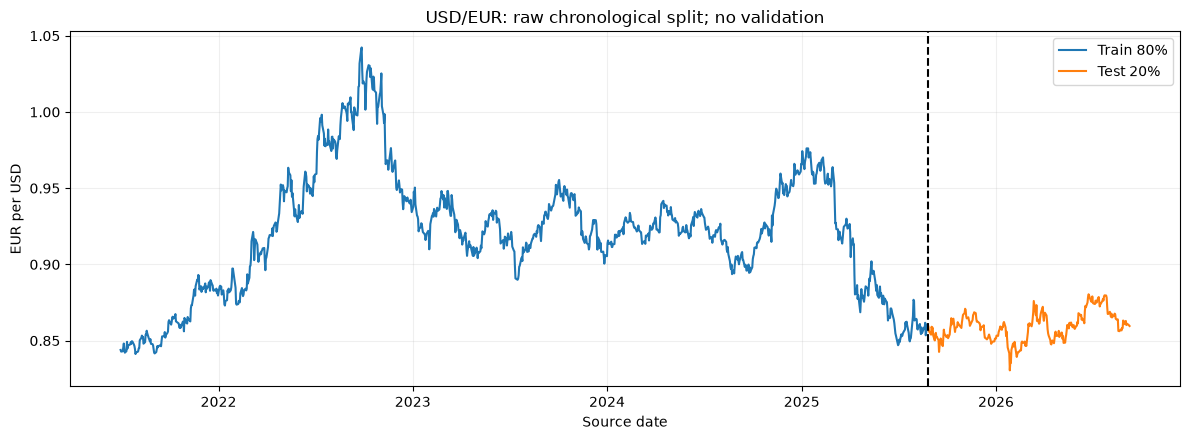

In [5]:
split_summary = pd.DataFrame([dict(partition=label, rows=b-a, start_date=df.index[a], end_date=df.index[b-1])
                             for label,a,b in [('Train',0,n_train),('Test',n_train,n)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots()
ax.plot(df.index[:n_train], prices[:n_train], label='Train 80%')
ax.plot(df.index[n_train:], prices[n_train:], label='Test 20%')
ax.axvline(df.index[n_train], color='black', linestyle='--')
ax.set(title=f'{ASSET_NAME}: raw chronological split; no validation', ylabel=UNIT, xlabel='Source date')
ax.legend(); save_figure(fig, '01_raw_split.png')

## 6. Descriptive EDA
These full-sample plots describe the supplied data; model settings remain the previously declared ones.

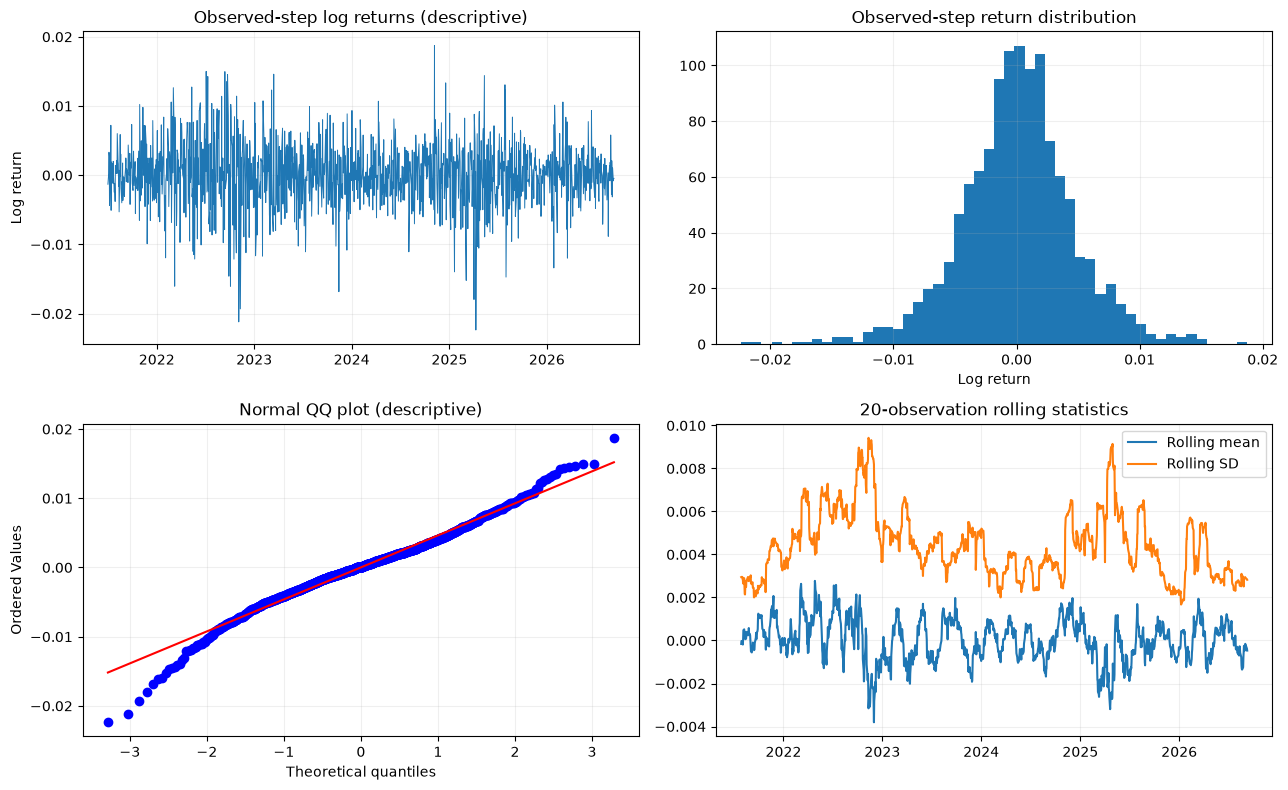

In [6]:
# Full-sample descriptive plots do not supply model settings or selection decisions.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(df.index[1:], returns[1:], linewidth=.7)
axes[0,0].set(title='Observed-step log returns (descriptive)', ylabel='Log return')
axes[0,1].hist(returns[1:], bins=50, density=True)
axes[0,1].set(title='Observed-step return distribution', xlabel='Log return')
stats.probplot(returns[1:], dist='norm', plot=axes[1,0])
axes[1,0].set_title('Normal QQ plot (descriptive)')
rolling = pd.Series(returns, index=df.index).rolling(ROLLING_WINDOW)
axes[1,1].plot(rolling.mean(), label='Rolling mean')
axes[1,1].plot(rolling.std(), label='Rolling SD')
axes[1,1].set_title(f'{ROLLING_WINDOW}-observation rolling statistics')
axes[1,1].legend(); save_figure(fig, '02_descriptive_eda.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'EUR per USD'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,EUR per USD,EUR per USD,EUR per USD
Start,2021-07-01,2021-07-01,2025-08-27
End,2026-09-09,2025-08-26,2026-09-09
Count,1355,1084,271
Mean,0.907759,0.919844,0.859418
SD,0.04339,0.040014,0.009333
Min,0.8305,0.8412,0.8305
Q1,0.86525,0.89375,0.85285
Median,0.9136,0.9212,0.8594
Q3,0.93435,0.94245,0.8652


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-27
End,2026-09-09,2025-08-26,2026-09-09
Count,1354,1083,271
Mean,0.000014,0.000016,0.000003
SD,0.004666,0.004927,0.003437
Min,-0.022368,-0.022368,-0.013396
Q1,-0.002571,-0.002723,-0.002022
Median,0.000109,0.000109,0.000116
Q3,0.002583,0.002724,0.002068


## 8. Direct horizon models: Train windows, fitting and diagnostics
Inputs are oldest to newest; every target remains inside raw Train. SVR uses the reference analytical C/epsilon rule with three other nearest Train windows (self excluded), not cross-validation. XGBoost uses fixed settings and monitors only identical fitting data. No early stopping or held-out monitoring. Training residual tests are reporting-only.

XGBOOST h=1: fitted 1043 Train windows


XGBOOST h=3: fitted 1041 Train windows


XGBOOST h=5: fitted 1039 Train windows


XGBOOST h=7: fitted 1037 Train windows


XGBOOST h=14: fitted 1030 Train windows


XGBOOST h=21: fitted 1023 Train windows


XGBOOST h=30: fitted 1014 Train windows


,h,n_estimators,first_train_RMSE,final_train_RMSE,n_train,warnings,status,train_RMSE_log_return
0,1,100,0.004679,0.000620,1043,,REPORTED,0.000620
1,3,100,0.008041,0.000629,1041,,REPORTED,0.000629
2,5,100,0.010279,0.000607,1039,,REPORTED,0.000607
3,7,100,0.012045,0.000628,1037,,REPORTED,0.000628
4,14,100,0.016649,0.000611,1030,,REPORTED,0.000611
5,21,100,0.020991,0.000641,1023,,REPORTED,0.000641
6,30,100,0.025559,0.000681,1014,,REPORTED,0.000681


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Train cumulative log-return errors h=1,Ljung-Box lag 10,7.184268,7.079419e-01,REPORTED,No rejection of residual independence; model_d...
1,Train cumulative log-return errors h=1,Ljung-Box lag 20,11.605286,9.289922e-01,REPORTED,No rejection of residual independence; model_d...
2,Train cumulative log-return errors h=1,Ljung-Box lag 30,13.906842,9.946056e-01,REPORTED,No rejection of residual independence; model_d...
3,Train cumulative log-return errors h=1,Residual mean t-test,-0.000002,9.999984e-01,REPORTED,"Mean=-3.7731419e-11; descriptive, dependent er..."
4,Train cumulative log-return errors h=1,ARCH LM,49.495759,3.303775e-07,REPORTED,Conditional variance evidence; no retuning
5,Train cumulative log-return errors h=1,Jarque-Bera,475.234790,6.369077e-104,REPORTED,Normality diagnostic; skew=0.29705; kurtosis=6...


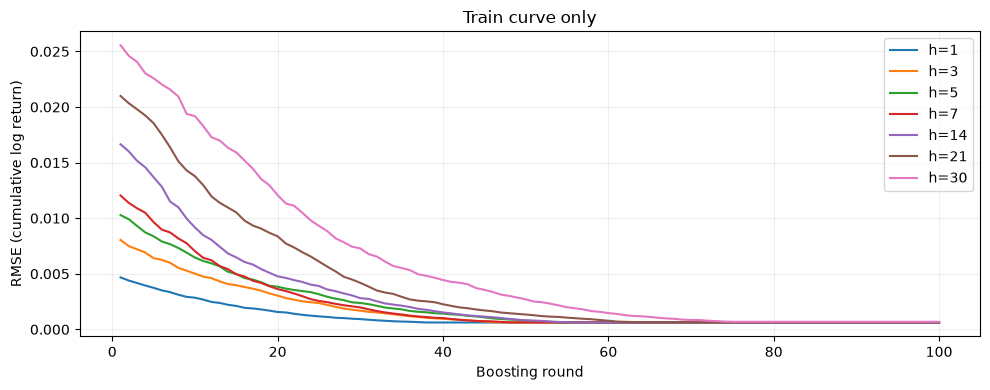

In [7]:
models, target_scalers, frozen_hashes, provenance, fit_rows, curve_rows, gain_rows = {}, {}, {}, [], [], [], []
feature_names = [f'return_lag_{lag}' for lag in range(LOOKBACK-1,-1,-1)]
training_residuals = {}
for h in HORIZONS:
    origins = np.arange(LOOKBACK, n_train-h)
    idx = origins[:,None] - np.arange(LOOKBACK-1,-1,-1)[None,:]
    targets = origins + h
    check(f'h={h}: Train target boundary', targets.max() == T and idx.min() == 1)
    check(f'h={h}: Train sample count', len(origins) == n_train-LOOKBACK-h)
    # Chronological feature ordering is identical at fit and inference for both estimators.
    X = (z if MODEL == 'SVR' else returns)[idx]
    y = log_price[targets] - log_price[origins]
    audit = pd.DataFrame(dict(origin_index=origins, origin_date=df.index[origins],
        input_start_date=df.index[idx[:,0]], input_end_date=df.index[idx[:,-1]], target_date=df.index[targets]))
    save_table(audit, f'training_window_audit_h{h}.csv')
    provenance.append(dict(h=h, n_train=len(origins), input_start_index=int(idx.min()),
        input_end_index=int(idx.max()), target_end_index=int(targets.max()), target_end_date=df.index[targets.max()]))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        if MODEL == 'SVR':
            target_scaler = StandardScaler().fit(y[:,None])
            target_scalers[h] = target_scaler
            ys = target_scaler.transform(y[:,None]).ravel()
            k = SETTINGS['knn_k']
            assert len(y)>k and X.var()>0 and ys.std()>0
            neighbors = NearestNeighbors(n_neighbors=k+1).fit(X).kneighbors(X, return_distance=False)
            others = np.stack([v[v != i][:k] for i,v in enumerate(neighbors)])
            assert others.shape == (len(y),k) and (others != np.arange(len(y))[:,None]).all()
            mse_knn = np.mean((ys-ys[others].mean(axis=1))**2)
            a = len(y)**.2*k
            sigma = np.sqrt(a/(a-1)*mse_knn)
            C = max(abs(ys.mean()+3*ys.std(ddof=0)), abs(ys.mean()-3*ys.std(ddof=0)))
            epsilon = 3*sigma*np.sqrt(np.log(len(y))/len(y))
            model = SVR(kernel=SETTINGS['kernel'], gamma=SETTINGS['gamma'], C=C, epsilon=epsilon)
            model.fit(X,ys)
            fitted = target_scaler.inverse_transform(model.predict(X)[:,None]).ravel()
            row = dict(h=h, C=C, epsilon=epsilon, sigma_hat=sigma, gamma=model._gamma,
                support_vectors=int(model.n_support_.sum()), support_vector_pct=100*model.n_support_.sum()/len(y),
                fit_status=int(model.fit_status_), scaled_train_RMSE=float(np.sqrt(np.mean((ys-model.predict(X))**2))),
                target_scaler_mean=float(target_scaler.mean_[0]), target_scaler_scale=float(target_scaler.scale_[0]),
                target_scaler_n=int(target_scaler.n_samples_seen_))
            joblib.dump(model, MODEL_DIR/f'svr_h{h}.joblib')
            joblib.dump(target_scaler, MODEL_DIR/f'target_scaler_h{h}.joblib')
            frozen_hashes[h] = joblib.hash((model,scaler,target_scaler))
            check(f'h={h}: SVR successful fit', model.fit_status_ == 0 and not any(issubclass(w.category,ConvergenceWarning) for w in caught))
        else:
            model = XGBRegressor(**SETTINGS)
            # Identical fitting observations only: validation_0 is an API label, not a validation split.
            model.fit(X,y,eval_set=[(X,y)],verbose=False)
            fitted = model.predict(X)
            losses = model.evals_result()['validation_0']['rmse']
            curve_rows.extend(dict(h=h, iteration=i+1, train_RMSE=value) for i,value in enumerate(losses))
            raw_gain = model.get_booster().get_score(importance_type='gain')
            gain_rows.extend(dict(h=h, feature=feature_names[j], lag=LOOKBACK-1-j, gain=raw_gain.get(f'f{j}',0.)) for j in range(LOOKBACK))
            row = dict(h=h, n_estimators=model.get_booster().num_boosted_rounds(), first_train_RMSE=losses[0], final_train_RMSE=losses[-1])
            check(f'h={h}: XGBoost fixed training budget', model.get_booster().num_boosted_rounds() == SETTINGS['n_estimators'] and np.isfinite(losses).all())
            model.save_model(MODEL_DIR/f'xgboost_h{h}.json')
            frozen_hashes[h] = hashlib.sha256(model.get_booster().save_raw()).hexdigest()
    row.update(n_train=len(y), warnings=warning_text(caught), status='REPORTED',
               train_RMSE_log_return=float(np.sqrt(np.mean((y-fitted)**2))))
    models[h] = model
    fit_rows.append(row)
    training_residuals[h] = y-fitted
    print(f'{MODEL} h={h}: fitted {len(y)} Train windows', flush=True)
fit_audit = pd.DataFrame(fit_rows)
save_table(fit_audit, 'training_fit.csv')
save_table(pd.DataFrame(provenance), 'training_provenance.csv')
display(fit_audit)
train_diagnostics = residual_report(training_residuals[HORIZONS[0]], f'Train cumulative log-return errors h={HORIZONS[0]}')
save_table(train_diagnostics, 'train_residual_diagnostics.csv'); display(train_diagnostics)
if MODEL == 'XGBOOST':
    curves, gains = pd.DataFrame(curve_rows), pd.DataFrame(gain_rows)
    save_table(curves,'training_curves.csv'); save_table(gains,'gain_importance.csv')
    fig,ax=plt.subplots(figsize=(10,4))
    for h in HORIZONS:
        c=curves.loc[curves.h.eq(h)]
        ax.plot(c.iteration,c.train_RMSE,label=f'h={h}')
    ax.set(title='Train curve only',xlabel='Boosting round',ylabel='RMSE (cumulative log return)')
    ax.legend(); save_figure(fig,'03_training_curve.png')
def model_fingerprint():
    if MODEL == 'SVR': return {h:joblib.hash((models[h],scaler,target_scalers[h])) for h in HORIZONS}
    return {h:hashlib.sha256(models[h].get_booster().save_raw()).hexdigest() for h in HORIZONS}
frozen_state = model_fingerprint()
assert frozen_state == frozen_hashes
def predict_cumulative(origins):
    idx = np.asarray(origins)[:,None] - np.arange(LOOKBACK-1,-1,-1)[None,:]
    assert idx.min()>=1 and (idx<=np.asarray(origins)[:,None]).all()
    X=(z if MODEL=='SVR' else returns)[idx]
    result={}
    for h in HORIZONS:
        pred=models[h].predict(X)
        result[h]=target_scalers[h].inverse_transform(pred[:,None]).ravel() if MODEL=='SVR' else pred
    return result, {}

### 8.1 XGBoost PI 95% - Train-only quantile models

The existing squared-error point models and forecasts remain unchanged. Separate `reg:quantileerror` models estimate the 2.5% and 97.5% quantiles of cumulative log returns for horizons 1 through 30. They use the same Train windows, original fixed tree settings and budgets, with no validation, early stopping, Test tuning or all-data refit.

Columns `xgb_lo95` and `xgb_hi95` are the nominal central 95% prediction bounds in the original price units. Quantile crossings are disclosed and resolved by a fixed row-wise ordering before exponentiation. The original point forecast is not used to stretch bounds.

These are estimated quantile intervals, not conformally calibrated intervals or a guarantee of 95% coverage under time dependence or regime changes. Test coverage below is reporting only and never changes the bounds.

Method reference: [Official XGBoost quantile regression example](https://xgboost.readthedocs.io/en/release_2.0.0/python/examples/quantile_regression.html).


In [8]:
# Nominal central 95% prediction intervals from separate Train-only quantile models.
# Do not tune or calibrate these bounds using Test outcomes.
assert tuple(int(v) for v in version('xgboost').split('.')[:2]) >= (2, 0)
pi_params = dict(SETTINGS)
pi_params.update(objective='reg:quantileerror', quantile_alpha=XGB_PI_QUANTILES)
assert SETTINGS['objective'] == 'reg:squarederror'
xgb_pi_models, xgb_pi_hashes, xgb_pi_fit_rows = {}, {}, []
xgb_pi_crossing_rows = []
for h in range(1, max(DAILY_FORECAST_WINDOWS)+1):
    pi_origins = np.arange(LOOKBACK, T-h+1)
    pi_input_idx = pi_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
    pi_target_idx = pi_origins+h
    assert pi_input_idx.min() >= 1 and pi_target_idx.max() == T
    assert (pi_input_idx <= pi_origins[:, None]).all()
    assert len(pi_origins) == n_train-LOOKBACK-h
    pi_X = returns[pi_input_idx]
    pi_y = np.asarray(log_price)[pi_target_idx]-np.asarray(log_price)[pi_origins]
    assert np.isfinite(pi_X).all() and np.isfinite(pi_y).all()
    pi_model = XGBRegressor(**pi_params)
    with warnings.catch_warnings(record=True) as pi_warnings:
        warnings.simplefilter('always')
        pi_model.fit(pi_X, pi_y, verbose=False)
    assert pi_model.get_booster().num_boosted_rounds() == SETTINGS['n_estimators']
    xgb_pi_models[h] = pi_model
    xgb_pi_hashes[h] = hashlib.sha256(pi_model.get_booster().save_raw()).hexdigest()
    xgb_pi_fit_rows.append(dict(h=h, n_train=len(pi_origins),
        input_max_index=int(pi_input_idx.max()), target_max_index=int(pi_target_idx.max()),
        target_max_date=df.index[pi_target_idx.max()], lower_quantile=XGB_PI_QUANTILES[0],
        upper_quantile=XGB_PI_QUANTILES[1], nominal_coverage=1-XGB_PI_ALPHA,
        warnings=' | '.join(str(w.message) for w in pi_warnings)))
    pi_model.save_model(MODEL_DIR/f'xgb_pi_h{h}.json')
xgb_pi_fit_audit = pd.DataFrame(xgb_pi_fit_rows)
save_table(xgb_pi_fit_audit, 'xgb_pi_training_audit.csv')
display(Markdown('**PI models: Train-only cumulative-return quantiles, fixed budgets**'))
show_table(xgb_pi_fit_audit)

def attach_xgb_pi(frame, label):
    result = frame.copy(deep=True)
    previous_columns = list(frame.columns)
    lower = np.empty(len(frame), dtype=float)
    upper = np.empty(len(frame), dtype=float)
    for h in sorted(frame['h'].unique()):
        positions = np.flatnonzero(frame['h'].to_numpy() == h)
        origins = df.index.get_indexer(pd.to_datetime(frame['origin_date'].iloc[positions]))
        assert (origins >= LOOKBACK).all()
        idx = origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
        assert idx.min() >= 1 and (idx <= origins[:, None]).all()
        X = returns[idx]
        pi_model = xgb_pi_models[int(h)]
        assert hashlib.sha256(pi_model.get_booster().save_raw()).hexdigest() == xgb_pi_hashes[int(h)]
        quantiles = pi_model.predict(X).astype(np.float64)
        assert quantiles.shape == (len(positions), 2) and np.isfinite(quantiles).all()
        crossed = quantiles[:, 0] > quantiles[:, 1]
        # Fixed monotone rearrangement; log ordering is preserved by exponentiation.
        ordered = np.sort(quantiles, axis=1)
        anchors = frame['price_origin'].iloc[positions].to_numpy(dtype=float)
        lower[positions] = anchors*np.exp(ordered[:, 0])
        upper[positions] = anchors*np.exp(ordered[:, 1])
        assert hashlib.sha256(pi_model.get_booster().save_raw()).hexdigest() == xgb_pi_hashes[int(h)]
        xgb_pi_crossing_rows.append(dict(table=label, h=int(h), n=len(positions),
            raw_quantile_crossings=int(crossed.sum()), action='Fixed row-wise quantile ordering'))
    result['xgb_lo95'] = lower
    result['xgb_hi95'] = upper
    assert np.isfinite(result[['xgb_lo95','xgb_hi95']]).all().all()
    assert (result.xgb_lo95 > 0).all() and (result.xgb_lo95 <= result.xgb_hi95).all()
    # Preserve every existing point forecast, actual, date and row exactly.
    pd.testing.assert_frame_equal(result[previous_columns], frame)
    save_table(pd.DataFrame(xgb_pi_crossing_rows), 'xgb_pi_crossing_audit.csv')
    return result


**PI models: Train-only cumulative-return quantiles, fixed budgets**

h,n_train,input_max_index,target_max_index,target_max_date,lower_quantile,upper_quantile,nominal_coverage,warnings
1,1043,1082,1083,2025-08-26,0.025000,0.975000,0.950000,
2,1042,1081,1083,2025-08-26,0.025000,0.975000,0.950000,
3,1041,1080,1083,2025-08-26,0.025000,0.975000,0.950000,
4,1040,1079,1083,2025-08-26,0.025000,0.975000,0.950000,
5,1039,1078,1083,2025-08-26,0.025000,0.975000,0.950000,
6,1038,1077,1083,2025-08-26,0.025000,0.975000,0.950000,
7,1037,1076,1083,2025-08-26,0.025000,0.975000,0.950000,
8,1036,1075,1083,2025-08-26,0.025000,0.975000,0.950000,
9,1035,1074,1083,2025-08-26,0.025000,0.975000,0.950000,
10,1034,1073,1083,2025-08-26,0.025000,0.975000,0.950000,


### 8.2 Gain importance (BTC Step 10 format)

Gain measures training split improvement, not causal influence or out-of-sample usefulness. Unused lags have zero gain. Raw gain values are shown; their magnitudes are not normalized across models with different target scales.

BTC-style reporting: heatmap across all horizons, Top 15 return lags for h=1, and the highest-gain lag for each horizon. Display lag_1 is the origin return; lag_40 is the oldest return. The display names map return_lag_0 to lag_1 through return_lag_39 to lag_40; fitted feature order stays unchanged. Horizons count observed records, not elapsed calendar days.


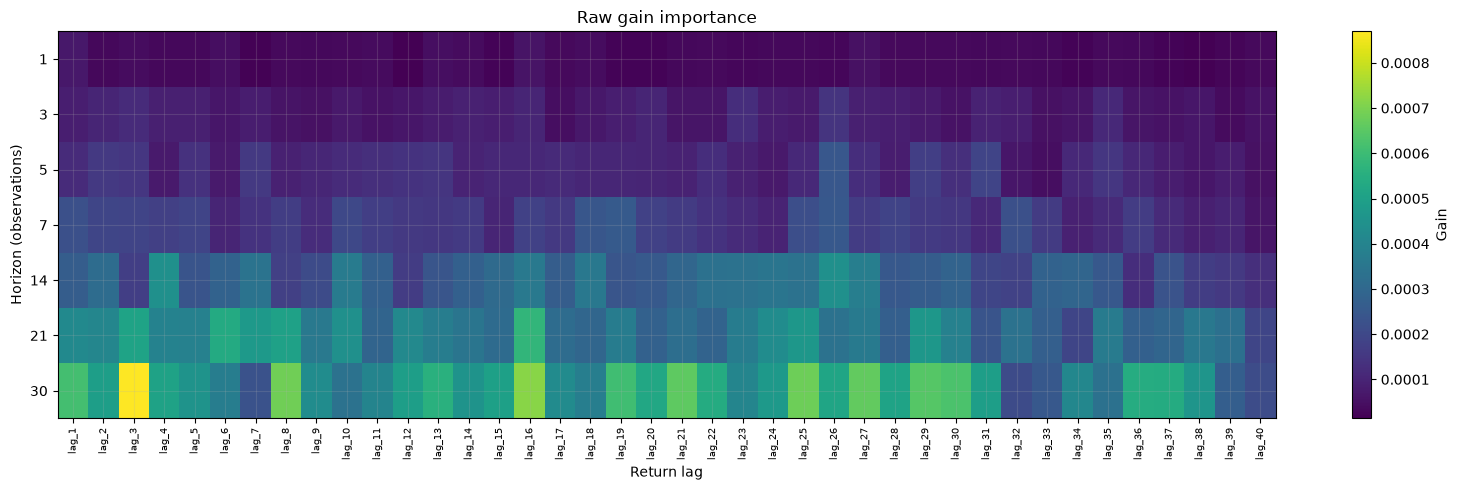

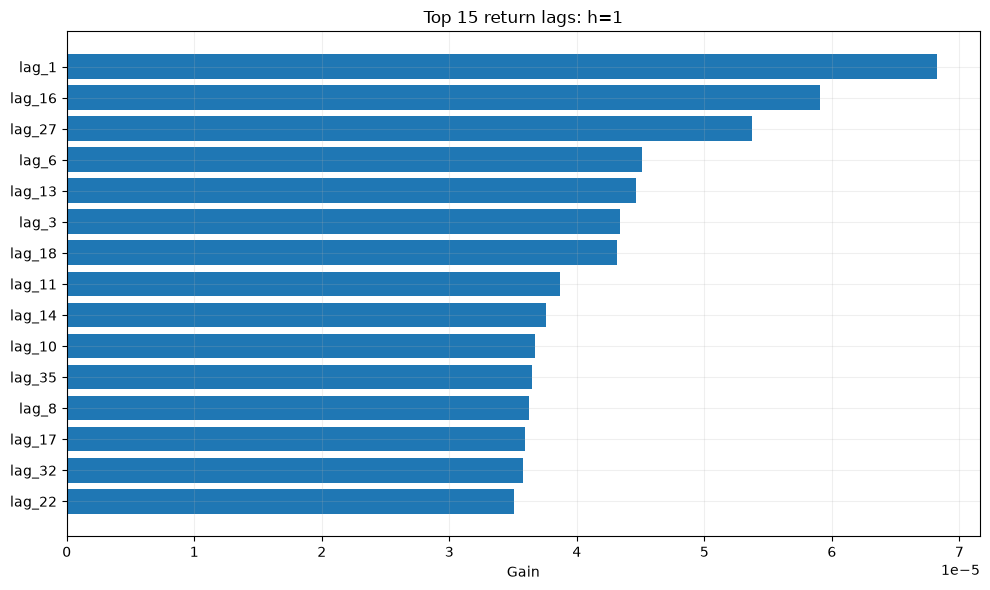

,h,feature,gain
0,1,lag_1,0.000068
1,3,lag_26,0.000144
2,5,lag_26,0.000247
3,7,lag_19,0.000257
4,14,lag_26,0.000444
5,21,lag_16,0.000577
6,30,lag_3,0.000870


In [9]:
# Display lag_1 as the origin return, matching BTC; preserve oldest-to-newest model inputs.
importance_features = [f'lag_{j}' for j in range(1, LOOKBACK+1)]
importance_rows=[]
for h in HORIZONS:
    gain=models[h].get_booster().get_score(importance_type='gain')
    importance_rows.extend(dict(h=h,feature=f,gain=float(gain.get(f'f{LOOKBACK-j}',0)))
        for j,f in enumerate(importance_features,1))
feature_importance=pd.DataFrame(importance_rows)
save_table(feature_importance,'feature_importance.csv')
heat=feature_importance.pivot(index='h',columns='feature',values='gain').reindex(index=HORIZONS,columns=importance_features)
fig,ax=plt.subplots(figsize=(16,5))
im=ax.imshow(heat.to_numpy(),aspect='auto',cmap='viridis')
ax.set(yticks=np.arange(len(HORIZONS)),yticklabels=HORIZONS,
    xticks=np.arange(LOOKBACK),xticklabels=importance_features,xlabel='Return lag',ylabel='Horizon (observations)',title='Raw gain importance')
ax.tick_params(axis='x',labelrotation=90,labelsize=7)
fig.colorbar(im,ax=ax,label='Gain')
save_figure(fig,'09_feature_importance_heatmap.png')
H1=next(h for h in HORIZONS if h==1)
top=feature_importance.loc[feature_importance.h.eq(H1)].nlargest(15,'gain').sort_values('gain')
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(top.feature,top.gain)
ax.set(title=f'Top 15 return lags: h={H1}',xlabel='Gain')
save_figure(fig,'10_feature_importance_h1.png')
top_by_horizon=feature_importance.loc[feature_importance.groupby('h').gain.idxmax()].reset_index(drop=True)
display(top_by_horizon)

### Step 10.1 - Lag ranking by Train Gain

**Ranking criterion:** descending XGBoost `gain`, separately for each forecast horizon from its fitted Train model. Gain is the average reduction in the training objective across splits using a feature. Rank 1 has the highest Gain; ties share a rank. Unused features have Gain = 0.

**Lag convention:** `lag_1` is the return observed at the forecast origin, `lag_2` is one observation before the origin, and `lag_40` is 39 observations before the origin. See `observations_before_origin` for explicit timing.

Separate tables show the Top 10 lags for **h=1, 3, 5, 7, 14, 21, 30 observations**, in that order. `highest_gain` flags the highest positive Gain within each horizon. Compare raw Gain within a horizon; target scales differ across horizons. The complete ranking for every horizon is still exported to `lag_ranking_by_gain.csv`.

**Interpretation:** these are importance ranks after fitting. All 40 return features remain available to the model. This does not select a subset, establish LOOKBACK=40 as optimal, or prove causality or out-of-sample usefulness. No Test scores enter the ranking.


In [ ]:
# Rank all return lags from the existing Train-fitted feature importance.
lag_ranking = feature_importance[['h', 'feature', 'gain']].copy()
lag_ranking['observations_before_origin'] = lag_ranking['feature'].str.extract(r'lag_(\d+)', expand=False).astype(int) - 1
lag_ranking['rank'] = lag_ranking.groupby('h')['gain'].rank(method='min', ascending=False).astype(int)
lag_ranking['highest_gain'] = lag_ranking['rank'].eq(1) & lag_ranking['gain'].gt(0)
lag_ranking = lag_ranking.sort_values(
    ['h', 'rank', 'observations_before_origin'], kind='stable'
)[['h', 'rank', 'feature', 'observations_before_origin', 'gain', 'highest_gain']].reset_index(drop=True)
assert lag_ranking.groupby('h').size().eq(LOOKBACK).all()
assert not lag_ranking.duplicated(['h', 'feature']).any()
assert np.isfinite(lag_ranking['gain']).all() and lag_ranking['gain'].ge(0).all()
save_table(lag_ranking, 'lag_ranking_by_gain.csv')

# Show one Top 10 table per forecast horizon.
for horizon in HORIZONS:
    horizon_ranking = lag_ranking.loc[lag_ranking['h'].eq(horizon)]
    display(Markdown(f'**Top 10 lags for h={horizon} observations, ranked by Train Gain**'))
    display(horizon_ranking.head(10).style.format({'gain': '{:.9f}'}).hide(axis='index'))


**Top 10 lags for h=1 observations, ranked by Train Gain**

h,rank,feature,observations_before_origin,gain,highest_gain
1,1,lag_1,0,0.000068206,True
1,2,lag_16,15,0.000059047,False
1,3,lag_27,26,0.000053751,False
1,4,lag_6,5,0.000045087,False
1,5,lag_13,12,0.000044623,False
1,6,lag_3,2,0.000043415,False
1,7,lag_18,17,0.000043167,False
1,8,lag_11,10,0.000038690,False
1,9,lag_14,13,0.000037619,False
1,10,lag_10,9,0.000036759,False


**Top 10 lags for h=3 observations, ranked by Train Gain**

h,rank,feature,observations_before_origin,gain,highest_gain
3,1,lag_26,25,0.000144105,True
3,2,lag_23,22,0.000125936,False
3,3,lag_3,2,0.000117664,False
3,4,lag_35,34,0.000111434,False
3,5,lag_20,19,0.000103534,False
3,6,lag_16,15,0.000102132,False
3,7,lag_2,1,0.000101734,False
3,8,lag_31,30,0.000096083,False
3,9,lag_14,13,0.000091253,False
3,10,lag_4,3,0.000088879,False


**Top 10 lags for h=5 observations, ranked by Train Gain**

...

h,rank,feature,observations_before_origin,gain,highest_gain
14,1,lag_26,25,0.000443661,True
14,2,lag_4,3,0.000442627,False
14,3,lag_27,26,0.000380026,False
14,4,lag_10,9,0.000368683,False
14,5,lag_16,15,0.000359687,False
14,6,lag_18,17,0.000355259,False
14,7,lag_24,23,0.000345823,False
14,8,lag_7,6,0.000339090,False
14,9,lag_23,22,0.000337861,False
14,10,lag_25,24,0.000335300,False


**Top 10 lags for h=21 observations, ranked by Train Gain**

h,rank,feature,observations_before_origin,gain,highest_gain
21,1,lag_16,15,0.000577439,True
21,2,lag_6,5,0.000537454,False
21,3,lag_3,2,0.000509209,False
21,4,lag_8,7,0.000503955,False
21,5,lag_7,6,0.000472827,False
21,6,lag_29,28,0.000468034,False
21,7,lag_25,24,0.000465466,False
21,8,lag_10,9,0.000443511,False
21,9,lag_24,23,0.000431092,False
21,10,lag_1,0,0.000421623,False


**Top 10 lags for h=30 observations, ranked by Train Gain**

h,rank,feature,observations_before_origin,gain,highest_gain
30,1,lag_3,2,0.000869715,True
30,2,lag_16,15,0.000718852,False
30,3,lag_8,7,0.000685791,False
30,4,lag_25,24,0.000680794,False
30,5,lag_27,26,0.000663997,False
30,6,lag_21,20,0.000657113,False
30,7,lag_29,28,0.000644646,False
30,8,lag_30,29,0.000625791,False
30,9,lag_1,0,0.000614759,False
30,10,lag_19,18,0.000608642,False


## 9. Rolling-origin Test forecast calculation
Origins start at the last Train row. At each origin, prior observed Test history may update inputs/filtering states. It never changes fitted coefficients, weights, scalers or tree structure. A horizon-h forecast does not use actuals between its origin and target. Targets are actual source dates at row origin+h.

In [10]:
test_origins=np.arange(T,n-1)
cumulative, seed_cumulative = predict_cumulative(test_origins)
def assemble_forecasts(predictions):
    rows=[]
    for h in HORIZONS:
        valid=test_origins+h<n
        origins=test_origins[valid]
        pred=np.asarray(predictions[h])[valid]
        rows.append(pd.DataFrame(dict(h=h,origin_index=origins,target_index=origins+h,
            origin_date=df.index[origins],target_date=df.index[origins+h],price_origin=prices[origins],
            actual=prices[origins+h],forecast=prices[origins]*np.exp(pred),predicted_log_return=pred)))
    return pd.concat(rows,ignore_index=True)
forecasts=assemble_forecasts(cumulative)
forecasts = attach_xgb_pi(forecasts, 'test')
seed_forecasts={seed:assemble_forecasts(pred) for seed,pred in seed_cumulative.items()}

## 10. Historical Test forecast tables
All rows appear in scrollable tables and are exported separately by horizon. ARIMA supplies model-based 95% intervals; log point forecasts are conditional medians. Other models have no calibrated intervals.

In [11]:
save_table(forecasts,'test_forecasts_all.csv')
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'### Historical Test forecasts: h={h} observations ({UNIT})'))
    show_table(group.drop(columns=['origin_index','target_index','predicted_log_return']))

### Historical Test forecasts: h=1 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,xgb_lo95,xgb_hi95
1,2025-08-26,2025-08-27,0.859000,0.859200,0.859989,0.853437,0.865885
1,2025-08-27,2025-08-28,0.859200,0.856000,0.857004,0.854089,0.863623
1,2025-08-28,2025-08-29,0.856000,0.855800,0.857244,0.849601,0.862990
1,2025-08-29,2025-09-01,0.855800,0.853900,0.851399,0.849151,0.860800
1,2025-09-01,2025-09-02,0.853900,0.859100,0.854026,0.846684,0.859704
1,2025-09-02,2025-09-03,0.859100,0.857600,0.858562,0.854117,0.865122
1,2025-09-03,2025-09-04,0.857600,0.858500,0.857446,0.852688,0.862654
1,2025-09-04,2025-09-05,0.858500,0.853400,0.858021,0.853910,0.864926
1,2025-09-05,2025-09-08,0.853400,0.850100,0.855466,0.848125,0.858157
1,2025-09-08,2025-09-09,0.850100,0.854200,0.847915,0.845310,0.856380


### Historical Test forecasts: h=3 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,xgb_lo95,xgb_hi95
3,2025-08-26,2025-08-29,0.859000,0.855800,0.863019,0.850344,0.866088
3,2025-08-27,2025-09-01,0.859200,0.853900,0.858174,0.848378,0.869776
3,2025-08-28,2025-09-02,0.856000,0.859100,0.850936,0.846348,0.862768
3,2025-08-29,2025-09-03,0.855800,0.857600,0.854343,0.844981,0.864739
3,2025-09-01,2025-09-04,0.853900,0.858500,0.850590,0.846017,0.861678
3,2025-09-02,2025-09-05,0.859100,0.853400,0.860618,0.853620,0.870221
3,2025-09-03,2025-09-08,0.857600,0.850100,0.858558,0.851284,0.865442
3,2025-09-04,2025-09-09,0.858500,0.854200,0.862557,0.853081,0.867475
3,2025-09-05,2025-09-10,0.853400,0.855100,0.857205,0.844267,0.862125
3,2025-09-08,2025-09-11,0.850100,0.852300,0.848214,0.842732,0.857979


### Historical Test forecasts: h=5 observations (EUR per USD)

...

h,origin_date,target_date,price_origin,actual,forecast,xgb_lo95,xgb_hi95
14,2025-08-26,2025-09-15,0.859000,0.850300,0.864463,0.840101,0.881463
14,2025-08-27,2025-09-16,0.859200,0.842600,0.853161,0.838884,0.875696
14,2025-08-28,2025-09-17,0.856000,0.846600,0.848176,0.835851,0.866838
14,2025-08-29,2025-09-18,0.855800,0.848400,0.856431,0.835802,0.872544
14,2025-09-01,2025-09-19,0.853900,0.851400,0.850047,0.837487,0.863178
14,2025-09-02,2025-09-22,0.859100,0.847200,0.867547,0.843457,0.877507
14,2025-09-03,2025-09-23,0.857600,0.846400,0.868631,0.843792,0.869463
14,2025-09-04,2025-09-24,0.858500,0.851900,0.867954,0.849124,0.872716
14,2025-09-05,2025-09-25,0.853400,0.857200,0.853389,0.834293,0.865182
14,2025-09-08,2025-09-26,0.850100,0.854600,0.856393,0.832378,0.866276


### Historical Test forecasts: h=21 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,xgb_lo95,xgb_hi95
21,2025-08-26,2025-09-24,0.859000,0.851900,0.862008,0.843412,0.881887
21,2025-08-27,2025-09-25,0.859200,0.857200,0.850001,0.836524,0.878087
21,2025-08-28,2025-09-26,0.856000,0.854600,0.856308,0.835833,0.876752
21,2025-08-29,2025-09-29,0.855800,0.852800,0.851257,0.833779,0.883217
21,2025-09-01,2025-09-30,0.853900,0.852300,0.839004,0.834592,0.885266
21,2025-09-02,2025-10-01,0.859100,0.852500,0.859674,0.836284,0.888732
21,2025-09-03,2025-10-02,0.857600,0.853600,0.858362,0.838889,0.887090
21,2025-09-04,2025-10-03,0.858500,0.851600,0.855980,0.840430,0.879789
21,2025-09-05,2025-10-06,0.853400,0.854000,0.853378,0.829369,0.875451
21,2025-09-08,2025-10-07,0.850100,0.857900,0.858291,0.831381,0.875406


### Historical Test forecasts: h=30 observations (EUR per USD)

h,origin_date,target_date,price_origin,actual,forecast,xgb_lo95,xgb_hi95
30,2025-08-26,2025-10-07,0.859000,0.857900,0.847842,0.835206,0.885987
30,2025-08-27,2025-10-08,0.859200,0.860000,0.866887,0.836549,0.888744
30,2025-08-28,2025-10-09,0.856000,0.864700,0.857295,0.829362,0.883116
30,2025-08-29,2025-10-10,0.855800,0.860600,0.865171,0.832221,0.885667
30,2025-09-01,2025-10-13,0.853900,0.864400,0.858979,0.831944,0.891499
30,2025-09-02,2025-10-14,0.859100,0.861600,0.863628,0.837278,0.895257
30,2025-09-03,2025-10-15,0.857600,0.858600,0.856384,0.831601,0.885741
30,2025-09-04,2025-10-16,0.858500,0.855700,0.863421,0.832670,0.889115
30,2025-09-05,2025-10-17,0.853400,0.858300,0.857164,0.825670,0.883850
30,2025-09-08,2025-10-20,0.850100,0.859000,0.858744,0.828375,0.874808


## 11. Future forecasts from the latest observed origin
Same original Train parameters; no all-data refit. One row per horizon. Future dates are conditional weekday-pattern projections, explicitly distinct from observed historical target dates. No actual values or evaluation metrics exist for these rows.

In [12]:
# These are projected source-calendar dates, not verified exchange/holiday sessions.
future_dates=pd.date_range(df.index[-1]+calendar_offset,periods=MAX_H,freq=calendar_offset)
future_rows=[]
if MODEL=='ARIMA':
    latest_state=res.apply(log_price,refit=False)
    np.testing.assert_array_equal(latest_state.params,frozen_params)
    fc=latest_state.get_forecast(steps=MAX_H)
    means=np.asarray(fc.predicted_mean); intervals=np.asarray(fc.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=np.exp(means[h-1]),lower95=np.exp(intervals[h-1,0]),upper95=np.exp(intervals[h-1,1])))
else:
    latest,_=predict_cumulative(np.array([n-1]))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=prices[-1]*np.exp(latest[h][0])))
future_forecasts=pd.DataFrame(future_rows)
future_forecasts = attach_xgb_pi(future_forecasts, 'future_by_horizon')
save_table(future_forecasts,'future_forecasts.csv')
display(Markdown('### Future forecasts: common latest origin; original Train fit'))
show_table(future_forecasts)
print('Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.')
check('Fitted model and preprocessing remain frozen', model_fingerprint()==frozen_state,
      'Includes SVR scalers, XGBoost trees, LSTM weights or full PatchTST state including BatchNorm buffers.')
if MODEL in ['SVR','LSTM','TRANSFORMER']:
    check('Input scaler remains frozen',joblib.hash(scaler)==scaler_hash)
write_json(MODEL_DIR/'frozen_state_audit.json',dict(before=frozen_state,after=model_fingerprint(),
    original_fit_end_date=df.index[T],latest_observed_input_date=df.index[-1],refit=False))

### Future forecasts: common latest origin; original Train fit

h,origin_date,target_date,target_date_status,price_origin,forecast,xgb_lo95,xgb_hi95
1,2026-09-09,2026-09-10,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.861447,0.854933,0.865758
3,2026-09-09,2026-09-14,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.863271,0.852580,0.869144
5,2026-09-09,2026-09-16,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.862737,0.849071,0.872563
7,2026-09-09,2026-09-18,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.868315,0.851023,0.873120
14,2026-09-09,2026-09-29,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.865471,0.849787,0.880768
21,2026-09-09,2026-10-08,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.862464,0.847689,0.884932
30,2026-09-09,2026-10-21,"PROJECTED: weekday pattern, holidays/omissions unknown",0.859600,0.875367,0.839416,0.889071


Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.


### 11.1 Daily future forecast tables - next 7 and 30 steps

Horizons count future observations. Dates retain the declared source-weekday pattern, including Sunday for WTI; they are conditional projections with holidays and source omissions unknown. These are not 7/30 elapsed calendar days.

Reuses original direct-horizon models; fits only missing daily horizons on Train with the original settings/prescription. No interpolation, validation, Test tuning or refitting of existing models. No calibrated prediction intervals are supplied.

Exports `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under the existing model output directory.


In [13]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
future_forecast_daily['target_date_status'] = 'PROJECTED: weekday pattern, holidays/omissions unknown'
# Reuse original direct-horizon models; fit only missing horizons on Train.
daily_models = {h: models[h] for h in HORIZONS}
daily_hashes = {h: frozen_hashes[h] for h in HORIZONS}
daily_fit_rows = []
for h in range(1, daily_steps + 1):
    if h in models:
        continue
    origins = np.arange(LOOKBACK, T - h + 1)
    input_idx = origins[:, None] - np.arange(LOOKBACK - 1, -1, -1)[None, :]
    target_idx = origins + h
    assert input_idx.min() >= 1 and target_idx.max() == T
    assert (input_idx <= origins[:, None]).all()
    assert len(origins) == n_train - LOOKBACK - h
    X = returns[input_idx]
    y = np.asarray(log_price)[target_idx] - np.asarray(log_price)[origins]
    assert np.isfinite(X).all() and np.isfinite(y).all()
    model = XGBRegressor(**SETTINGS)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        # eval_set is the identical Train fitting data; no held-out monitoring.
        model.fit(X, y, eval_set=[(X, y)], verbose=False)
    losses = np.asarray(model.evals_result()['validation_0']['rmse'])
    assert len(losses) == SETTINGS['n_estimators'] and np.isfinite(losses).all()
    assert model.get_booster().num_boosted_rounds() == SETTINGS['n_estimators']
    fit_details = dict(n_estimators=len(losses), first_train_RMSE=float(losses[0]),
        final_train_RMSE=float(losses[-1]))
    model.save_model(MODEL_DIR/f'xgboost_h{h}.json')
    daily_models[h] = model
    daily_hashes[h] = hashlib.sha256(model.get_booster().save_raw()).hexdigest()
    daily_fit_rows.append(dict(h=h, n_train=len(origins), input_max_idx=int(input_idx.max()),
        target_max_idx=int(target_idx.max()), target_max_date=df.index[target_idx.max()],
        warnings=' | '.join(str(w.message) for w in caught), **fit_details))
daily_additional_fit_audit = pd.DataFrame(daily_fit_rows)
save_table(daily_additional_fit_audit, 'daily_additional_fit_audit.csv')
display(Markdown('**Train-only fitting audit for additional daily horizons**'))
show_table(daily_additional_fit_audit)
daily_idx = n - 1 - np.arange(LOOKBACK - 1, -1, -1)
daily_input = returns[daily_idx].reshape(1, LOOKBACK)
daily_values = []
for h in range(1, daily_steps + 1):
    model = daily_models[h]
    assert hashlib.sha256(model.get_booster().save_raw()).hexdigest() == daily_hashes[h]
    prediction = model.predict(daily_input)
    cumulative_return = prediction[0]
    daily_values.append(np.float64(daily_origin_price)*np.exp(cumulative_return))
    assert hashlib.sha256(model.get_booster().save_raw()).hexdigest() == daily_hashes[h]
future_forecast_daily['forecast'] = daily_values
future_forecast_daily = attach_xgb_pi(future_forecast_daily, 'future_daily')
daily_forecast_columns = ['forecast']
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['forecast']],
    future_forecasts.set_index('h').loc[HORIZONS, ['forecast']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} projected observations - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} {UNIT}**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all((TABLE_DIR/f'future_forecast_daily_{days}d.csv').is_file() for days in DAILY_FORECAST_WINDOWS)


**Train-only fitting audit for additional daily horizons**

h,n_train,input_max_idx,target_max_idx,target_max_date,warnings,n_estimators,first_train_RMSE,final_train_RMSE
2,1042,1081,1083,2025-08-26,,100,0.006628,0.000506
4,1040,1079,1083,2025-08-26,,100,0.009108,0.000573
6,1038,1077,1083,2025-08-26,,100,0.011205,0.000614
8,1036,1075,1083,2025-08-26,,100,0.012796,0.000608
9,1035,1074,1083,2025-08-26,,100,0.013437,0.000631
10,1034,1073,1083,2025-08-26,,100,0.014246,0.000604
11,1033,1072,1083,2025-08-26,,100,0.014927,0.000572
12,1032,1071,1083,2025-08-26,,100,0.015527,0.000678
13,1031,1070,1083,2025-08-26,,100,0.016199,0.000592
15,1029,1068,1083,2025-08-26,,100,0.017205,0.000694


**Next 7 projected observations - origin 2026-09-09, last observed price 0.859600 EUR per USD**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,xgb_lo95,xgb_hi95
2026-09-09,1,2026-09-10,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.861447,0.854933,0.865758
2026-09-09,2,2026-09-11,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.863668,0.852745,0.867750
2026-09-09,3,2026-09-14,Monday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.863271,0.852580,0.869144
2026-09-09,4,2026-09-15,Tuesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.865098,0.849931,0.872666
2026-09-09,5,2026-09-16,Wednesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.862737,0.849071,0.872563
2026-09-09,6,2026-09-17,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.862171,0.848344,0.874128
2026-09-09,7,2026-09-18,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.868315,0.851023,0.873120


**Next 30 projected observations - origin 2026-09-09, last observed price 0.859600 EUR per USD**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast,xgb_lo95,xgb_hi95
2026-09-09,1,2026-09-10,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.861447,0.854933,0.865758
2026-09-09,2,2026-09-11,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.863668,0.852745,0.867750
2026-09-09,3,2026-09-14,Monday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.863271,0.852580,0.869144
2026-09-09,4,2026-09-15,Tuesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.865098,0.849931,0.872666
2026-09-09,5,2026-09-16,Wednesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.862737,0.849071,0.872563
2026-09-09,6,2026-09-17,Thursday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.862171,0.848344,0.874128
2026-09-09,7,2026-09-18,Friday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.868315,0.851023,0.873120
2026-09-09,8,2026-09-21,Monday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.862715,0.849886,0.876736
2026-09-09,9,2026-09-22,Tuesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.861129,0.848950,0.877205
2026-09-09,10,2026-09-23,Wednesday,0.859600,"PROJECTED: weekday pattern, holidays/omissions unknown",0.858693,0.849321,0.875201


### 11.2 PI coverage on historical Test - reporting only

Nominal coverage is 95%; realized coverage and interval width are descriptive. Overlapping horizons, time dependence and regime changes limit interpretation. No settings are revised from this table.


In [14]:
xgb_pi_coverage_rows = []
for h, group in forecasts.groupby('h', sort=True):
    covered = group['actual'].between(group['xgb_lo95'], group['xgb_hi95'])
    xgb_pi_coverage_rows.append(dict(h=int(h), n=len(group), nominal_coverage_pct=95.,
        empirical_test_coverage_pct=float(100*covered.mean()),
        mean_interval_width=float((group['xgb_hi95']-group['xgb_lo95']).mean()),
        status='REPORTED', interpretation='Test reporting only; no recalibration or retuning'))
xgb_pi_test_coverage = pd.DataFrame(xgb_pi_coverage_rows)
save_table(xgb_pi_test_coverage, 'xgb_pi_test_coverage.csv')
display(xgb_pi_test_coverage)
display(Markdown('**Raw quantile crossing audit (ordering fixed before Test)**'))
display(pd.DataFrame(xgb_pi_crossing_rows))
assert all(hashlib.sha256(model.get_booster().save_raw()).hexdigest() == xgb_pi_hashes[h]
           for h, model in xgb_pi_models.items())


,h,n,nominal_coverage_pct,empirical_test_coverage_pct,mean_interval_width,status,interpretation
0,1,271,95.0,91.881919,0.011006,REPORTED,Test reporting only; no recalibration or retuning
1,3,269,95.0,86.988848,0.016394,REPORTED,Test reporting only; no recalibration or retuning
2,5,267,95.0,87.640449,0.020379,REPORTED,Test reporting only; no recalibration or retuning
3,7,265,95.0,87.924528,0.023771,REPORTED,Test reporting only; no recalibration or retuning
4,14,258,95.0,90.310078,0.033945,REPORTED,Test reporting only; no recalibration or retuning
5,21,251,95.0,90.438247,0.040707,REPORTED,Test reporting only; no recalibration or retuning
6,30,242,95.0,92.148760,0.049092,REPORTED,Test reporting only; no recalibration or retuning


**Raw quantile crossing audit (ordering fixed before Test)**

,table,h,n,raw_quantile_crossings,action
0,test,1,271,0,Fixed row-wise quantile ordering
1,test,3,269,0,Fixed row-wise quantile ordering
2,test,5,267,0,Fixed row-wise quantile ordering
3,test,7,265,0,Fixed row-wise quantile ordering
4,test,14,258,0,Fixed row-wise quantile ordering
5,test,21,251,0,Fixed row-wise quantile ordering
6,test,30,242,0,Fixed row-wise quantile ordering
7,future_by_horizon,1,1,0,Fixed row-wise quantile ordering
8,future_by_horizon,3,1,0,Fixed row-wise quantile ordering
9,future_by_horizon,5,1,0,Fixed row-wise quantile ordering


## 12. Process checks and RMSE/MAPE
Check all alignment, counts, unique origins, finite outputs and valid inverse transforms before scoring. Export offending rows and stop on failure; do not clip. Report RMSE in original units, MAPE in percent and sample size separately by horizon. Zero actuals make group MAPE undefined rather than changing the denominator.

In [15]:
def validate_forecasts(frame,label):
    cols=[c for c in ['actual','forecast','price_origin','lower95','upper95'] if c in frame]
    good=np.isfinite(frame[cols]).all(axis=1) & frame.forecast.gt(0)
    if 'actual' in frame: good &= frame.actual.gt(0)
    if 'lower95' in frame: good &= frame.lower95.gt(0) & frame.lower95.le(frame.forecast) & frame.forecast.le(frame.upper95)
    save_table(frame.loc[~good],f'{label}_offending_rows.csv')
    check(f'{label}: finite and valid log inversion',bool(good.all()),'No clipping or post-Test parameter revision.')
    check(f'{label}: unique origin/horizon',not frame.duplicated(['origin_date','h']).any())
    if 'target_index' in frame:
        check(f'{label}: target alignment',bool((frame.target_index==frame.origin_index+frame.h).all()) and
            (frame.target_index>=n_train).all() and (frame.target_index<n).all() and
            np.array_equal(pd.to_datetime(frame.target_date).to_numpy(),df.index[frame.target_index].to_numpy()) and
            np.array_equal(pd.to_datetime(frame.origin_date).to_numpy(),df.index[frame.origin_index].to_numpy()) and
            np.array_equal(frame.actual.to_numpy(),prices[frame.target_index]),
            'Dates come from actual observed row positions, never calendar-day addition.')
        for h in HORIZONS:
            check(f'{label}: h={h} count',int(frame.h.eq(h).sum())==n_test-h+1,statistic=int(frame.h.eq(h).sum()))
    else:
        check(f'{label}: future-only dates',bool((frame.target_date>df.index[-1]).all()) and len(frame)==len(HORIZONS))
validate_forecasts(forecasts,'test')
validate_forecasts(future_forecasts,'future')
def score(frame):
    rows=[]
    for h,g in frame.groupby('h',sort=True):
        actual=g.actual.to_numpy(); forecast=g.forecast.to_numpy()
        zero=int((actual==0).sum())
        rows.append(dict(h=h,n=len(g),first_target_date=g.target_date.min(),last_target_date=g.target_date.max(),
            RMSE=np.sqrt(np.mean((actual-forecast)**2)),MAPE=np.nan if zero else 100*np.mean(np.abs((actual-forecast)/actual)),
            zero_actuals=zero,RMSE_unit=UNIT,MAPE_unit='%'))
    return pd.DataFrame(rows)
evaluation=score(forecasts)
save_table(evaluation,'metrics_by_horizon.csv')
display(Markdown('### Historical Test RMSE and MAPE (after forecast tables)'))
display(evaluation)
seed_metrics=None
if seed_forecasts:
    frames=[]
    for seed,frame in seed_forecasts.items():
        validate_forecasts(frame,f'seed{seed}_test')
        save_table(frame,f'seed{seed}_test_forecasts.csv')
        metrics=score(frame); metrics.insert(0,'seed',seed); frames.append(metrics)
    seed_metrics=pd.concat(frames,ignore_index=True)
    save_table(seed_metrics,'seed_metrics.csv')
    seed_summary=seed_metrics.groupby('h').agg(RMSE_mean=('RMSE','mean'),RMSE_SD=('RMSE','std'),MAPE_mean=('MAPE','mean'),MAPE_SD=('MAPE','std')).reset_index()
    save_table(seed_summary,'seed_metric_summary.csv')
    display(Markdown('Individual seeds and sample SD (ddof=1); separate from return-space ensemble metrics'))
    display(seed_metrics); display(seed_summary)

### Historical Test RMSE and MAPE (after forecast tables)

,h,n,first_target_date,last_target_date,RMSE,MAPE,zero_actuals,RMSE_unit,MAPE_unit
0,1,271,2025-08-27,2026-09-09,0.003243,0.288874,0,EUR per USD,%
1,3,269,2025-08-29,2026-09-09,0.005602,0.500949,0,EUR per USD,%
2,5,267,2025-09-02,2026-09-09,0.007203,0.673524,0,EUR per USD,%
3,7,265,2025-09-04,2026-09-09,0.008198,0.745559,0,EUR per USD,%
4,14,258,2025-09-15,2026-09-09,0.011579,1.091240,0,EUR per USD,%
5,21,251,2025-09-24,2026-09-09,0.013481,1.267840,0,EUR per USD,%
6,30,242,2025-10-07,2026-09-09,0.015753,1.526688,0,EUR per USD,%


## 13. Forecast plots and reporting-only Test residual diagnostics
Higher horizons can have overlapping errors and different target counts. Descriptive diagnostic p-values and Train/Test scale comparisons do not trigger model changes.

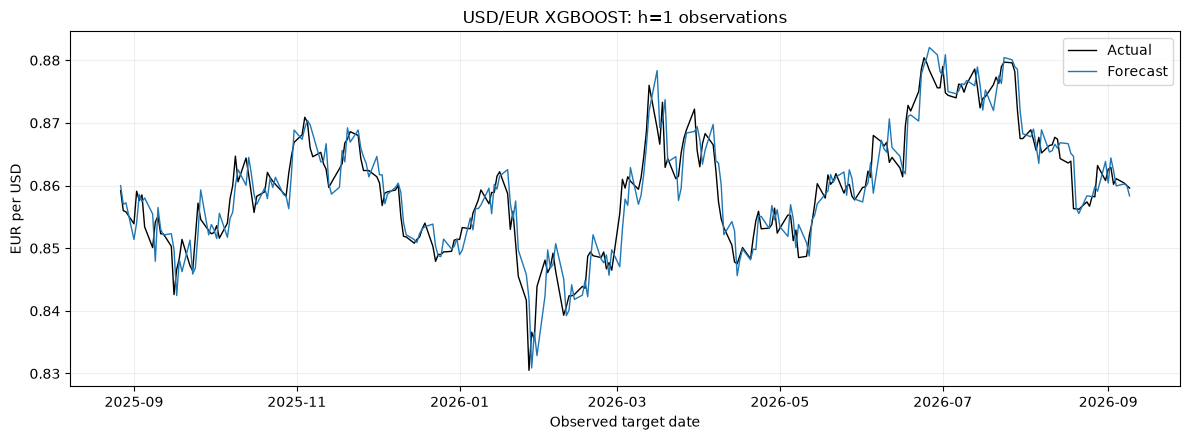

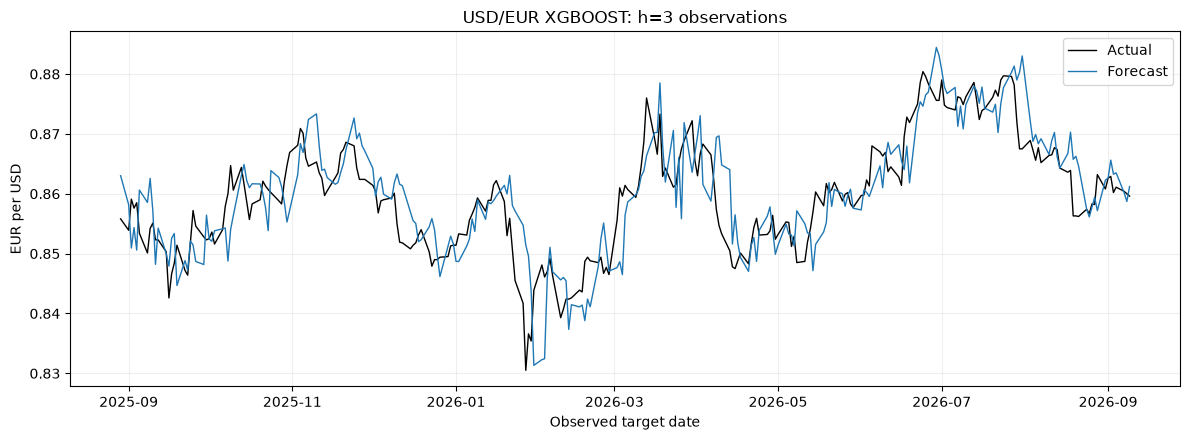

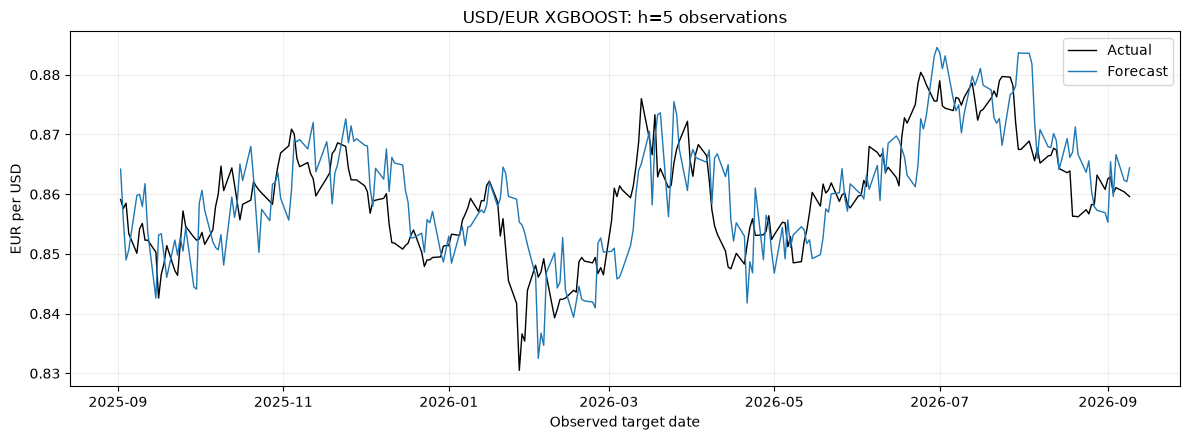

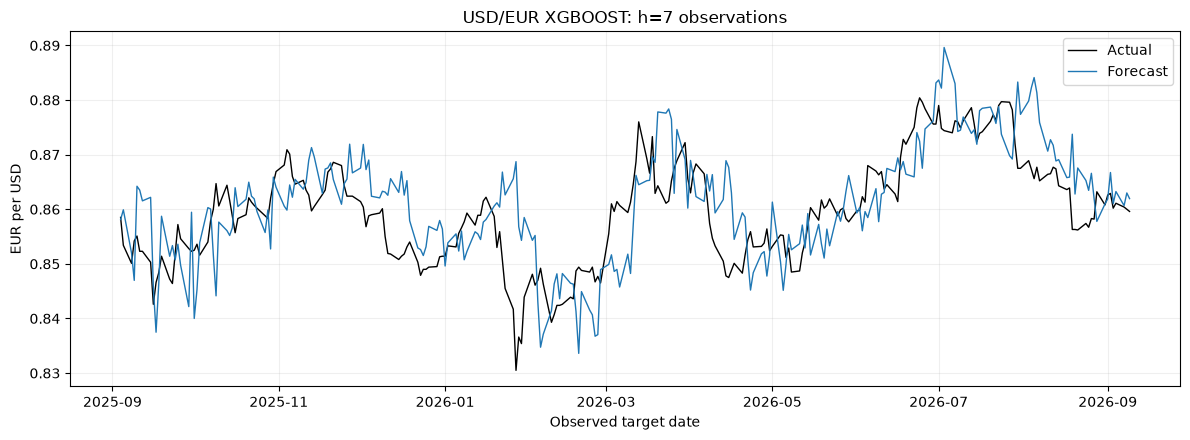

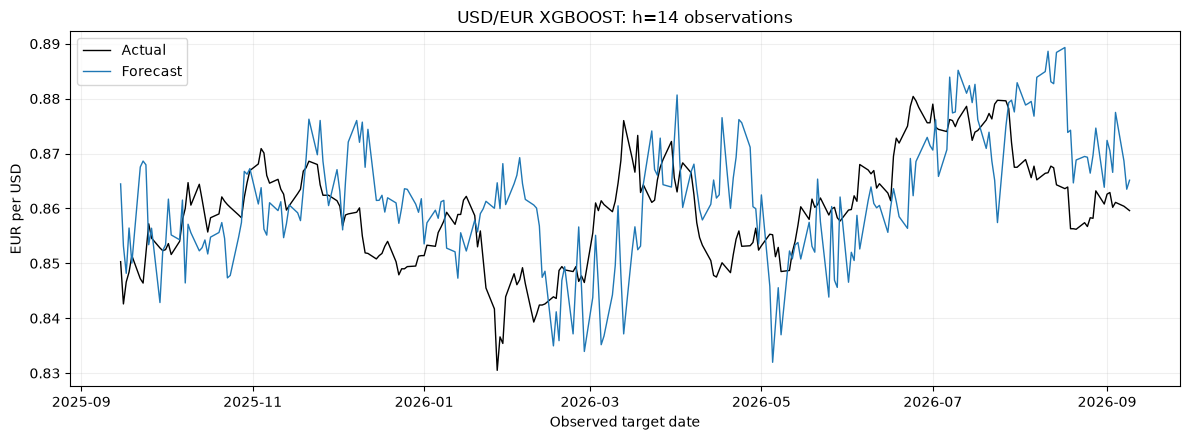

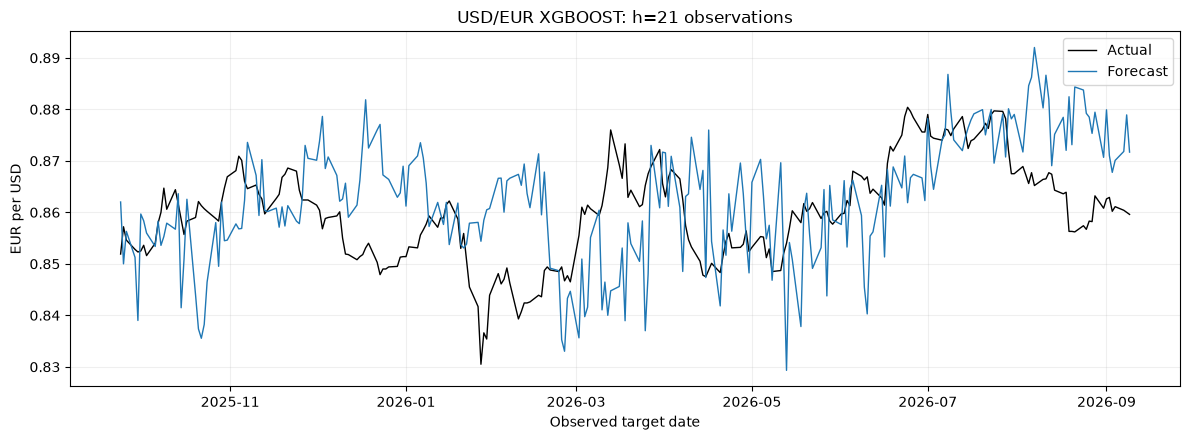

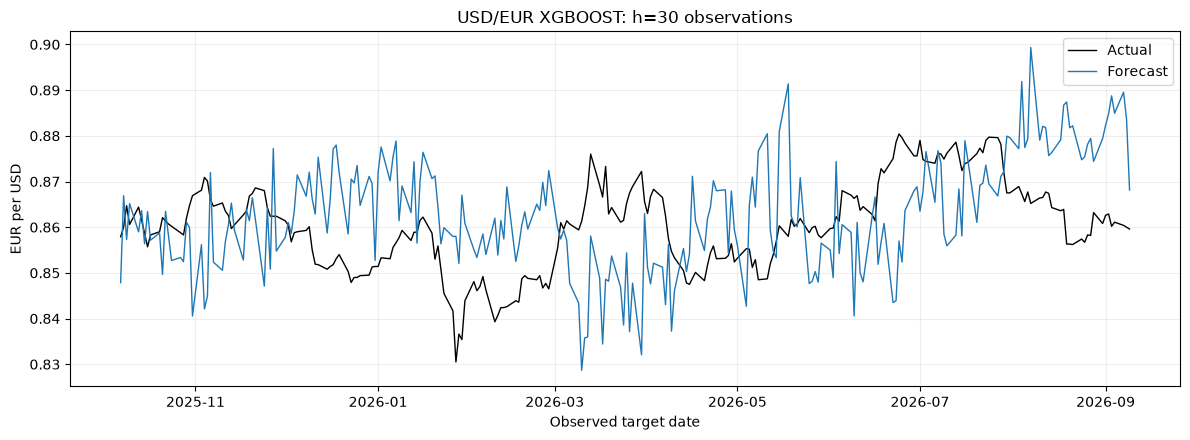

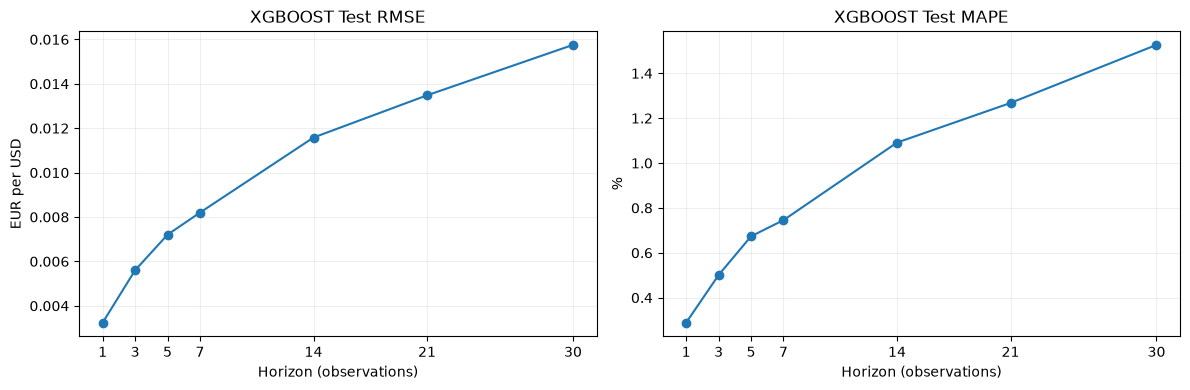

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 10,28.612064,0.001439,REPORTED,Evidence of serial correlation; model_df=0; re...
1,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 20,36.939069,0.011900,REPORTED,Evidence of serial correlation; model_df=0; re...
2,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 30,51.449728,0.008725,REPORTED,Evidence of serial correlation; model_df=0; re...
3,Test cumulative log-return errors h=1; reporti...,Residual mean t-test,-0.739171,0.460445,REPORTED,"Mean=-0.00016997604; descriptive, dependent er..."
4,Test cumulative log-return errors h=1; reporti...,ARCH LM,27.368909,0.002276,REPORTED,Conditional variance evidence; no retuning
5,Test cumulative log-return errors h=1; reporti...,Jarque-Bera,12.807098,0.001656,REPORTED,Normality diagnostic; skew=-0.053397; kurtosis...


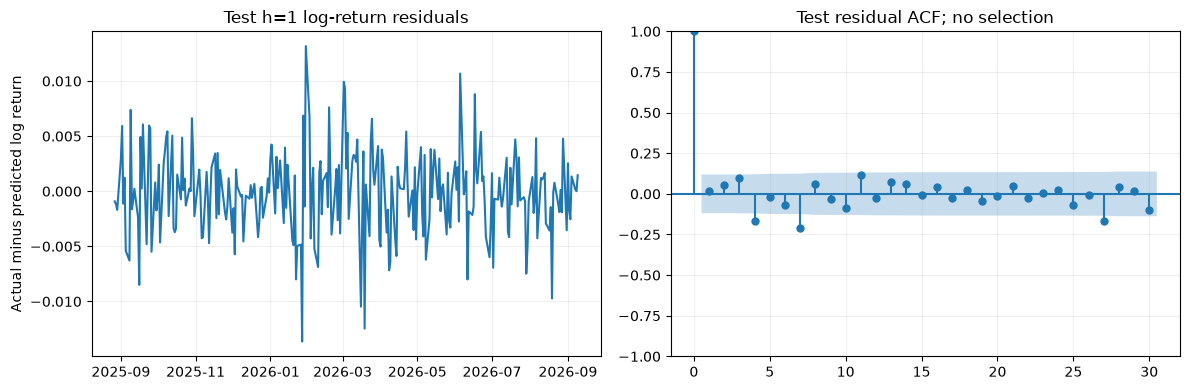

,sample,n,mean,SD,status
0,Train,1083,0.000016,0.004927,REPORTED
1,Test,271,0.000003,0.003437,REPORTED


In [16]:
for h in HORIZONS:
    g=forecasts.loc[forecasts.h.eq(h)].sort_values('target_date')
    fig,ax=plt.subplots()
    ax.plot(g.target_date,g.actual,label='Actual',color='black',linewidth=1)
    ax.plot(g.target_date,g.forecast,label='Forecast',linewidth=1)
    if 'lower95' in g: ax.fill_between(g.target_date,g.lower95,g.upper95,alpha=.2,label='Model-based 95% interval')
    ax.set(title=f'{ASSET_NAME} {MODEL}: h={h} observations',xlabel='Observed target date',ylabel=UNIT)
    ax.legend(); save_figure(fig,f'test_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],[UNIT,'%']):
    ax.plot(evaluation.h,evaluation[metric],marker='o')
    ax.set(title=f'{MODEL} Test {metric}',xlabel='Horizon (observations)',ylabel=unit,xticks=HORIZONS)
save_figure(fig,'metrics_by_horizon.png')
hdiag=HORIZONS[0]
g=forecasts.loc[forecasts.h.eq(hdiag)].sort_values('origin_date')
errors=np.log(g.actual/g.price_origin)-g.predicted_log_return
test_diagnostics=residual_report(errors,f'Test cumulative log-return errors h={hdiag}; reporting only')
save_table(test_diagnostics,'test_residual_diagnostics.csv'); display(test_diagnostics)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(g.target_date,errors); axes[0].set(title=f'Test h={hdiag} log-return residuals',ylabel='Actual minus predicted log return')
plot_acf(errors,lags=min(30,len(errors)//4),ax=axes[1]); axes[1].set_title('Test residual ACF; no selection')
save_figure(fig,'test_residual_diagnostics.png')
scale_comparison=pd.DataFrame([dict(sample='Train',n=n_train-1,mean=np.mean(returns[1:n_train]),SD=np.std(returns[1:n_train],ddof=1),status='REPORTED'),
    dict(sample='Test',n=n_test,mean=np.mean(returns[n_train:]),SD=np.std(returns[n_train:],ddof=1),status='REPORTED')])
save_table(scale_comparison,'return_scale_comparison.csv'); display(scale_comparison)

## 14. Summary generated from this execution
Rerunning regenerates this report from current results; there is no copied saved-result markdown.

In [17]:
lines=[f'# {ASSET_NAME} - {MODEL}: results from this execution','',
    f'Source: `{DATA_PATH.name}`; target: {TARGET_COL}; units: {UNIT}.',ASSET_NOTE,'',
    f'Raw chronological Train/Test: {n_train}/{n_test}; no validation.',
    f'Train: {df.index[0].date()} to {df.index[T].date()}; Test: {df.index[n_train].date()} to {df.index[-1].date()}.',
    f'Horizons: {HORIZONS} observations. Lookback: {LOOKBACK} observed returns for window models.',CALENDAR_NOTE,
    f'Source calendar audit: {len(missing_dates)} dates absent relative to the declared weekday pattern; maximum gap {int(gaps.calendar_days.max())} calendar days.',
    'Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.',
    'Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.','',
    '## Model development']
if MODEL=='ARIMA':
    lines += [f'Selected {selected.model}; Train AIC={selected.AIC:.6f}; BIC={selected.BIC:.6f}.',
        'Differencing is the smallest Train ADF/KPSS-supported order. Selection uses AIC among converged fits with valid roots. Residual tests are reported without retuning.',
        'Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means. The 95% intervals are model-based; ARCH/non-normality and calendar irregularity limit interpretation.']
    if int(selected.p)==0 and d==1 and int(selected.q)==0 and selected.trend=='n':
        lines.append('ARIMA(0,1,0) without drift gives the latest observed price as the point forecast; uncertainty increases with horizon.')
elif MODEL=='SVR':
    lines += ['Direct cumulative-log-return RBF models use the fixed Train-only C/epsilon heuristic and Train input/target scalers. No hyperparameter cross-validation.']
elif MODEL=='XGBOOST':
    lines += ['Direct cumulative-log-return models use a fixed predeclared configuration. Learning curves are fitting data only. Raw gain is neither causal importance nor proof of future usefulness.']
    lines += ['', '## Most important training lag by gain', markdown_table(top_by_horizon),
        'Display lag_1 is the origin return; lag_40 is the oldest input. Gain is Train-only and unnormalized.']
else:
    lines += [f'MIMO predicts the next {MAX_H} individual observed-step log returns; prices compound the predicted path only.',
        f'All predefined seeds {SEEDS} are included equally; {EPOCHS} fixed epochs each. Average inverse-scaled returns before compounding.',
        'Ensemble metrics are not the mean seed metrics. Seed metric SD uses ddof=1 and is not a prediction interval.']
lines += ['', '## Historical Test metrics',markdown_table(evaluation),'',
    'Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.',
    'MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.',
    '', '## Future forecasts (no actuals or metrics)',markdown_table(future_forecasts),'',
    'Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.',
    '', '## Checks and limitations',
    f'Process checks: {sum(row["status"]=="PASS" for row in process_rows)} passed; {sum(row["status"]=="FAIL" for row in process_rows)} failed.',
    'Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.',
    'No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.',
    'Test findings did not change parameters, epochs, transformations, seeds, or model selection.',
    'These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.',
    f'All rows, figures, summaries and fitted artifacts are under OUTPUT/{MODEL}_{ASSET}/.',
    f'Tested Python executable: {sys.executable}.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
lines += ['', '**XGBoost prediction intervals**', 'xgb_lo95/xgb_hi95: nominal central 95% Train-only quantile intervals; no Test calibration or tuning. Fixed quantile rearrangement is audited. Empirical Test coverage is reported separately; 95% coverage is not guaranteed.']
summary='\n\n'.join(lines)
(SUMMARY_DIR/'execution_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
write_json(SUMMARY_DIR/'execution_audit.json',dict(completed=True,asset=ASSET,model=MODEL,
    n=n,n_train=n_train,n_test=n_test,horizons=HORIZONS,counts={int(h):int(c) for h,c in forecasts.groupby('h').size().items()},
    train_end=str(df.index[T].date()),test_start=str(df.index[n_train].date()),last_observation=str(df.index[-1].date()),
    parameters_frozen=model_fingerprint()==frozen_state,process_checks=process_rows,
    source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),seed_count=len(seed_forecasts),python_executable=sys.executable))

# USD/EUR - XGBOOST: results from this execution



Source: `USD_EUR_Historical.csv`; target: Price; units: EUR per USD.

Quote direction follows USD/EUR in the supplied filename: EUR for one USD. The CSV does not specify fixing time or timezone.



Raw chronological Train/Test: 1084/271; no validation.

Train: 2021-07-01 to 2025-08-26; Test: 2025-08-27 to 2026-09-09.

Horizons: [1, 3, 5, 7, 14, 21, 30] observations. Lookback: 40 observed returns for window models.

Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.

Source calendar audit: 0 dates absent relative to the declared weekday pattern; maximum gap 3 calendar days.

Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.

Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.



## Model development

Direct cumulative-log-return models use a fixed predeclared configuration. Learning curves are fitting data only. Raw gain is neither causal importance nor proof of future usefulness.



## Most important training lag by gain

| h | feature | gain |
| --- | --- | --- |
| 1 | lag_1 | 0.000068 |
| 3 | lag_26 | 0.000144 |
| 5 | lag_26 | 0.000247 |
| 7 | lag_19 | 0.000257 |
| 14 | lag_26 | 0.000444 |
| 21 | lag_16 | 0.000577 |
| 30 | lag_3 | 0.000870 |

Display lag_1 is the origin return; lag_40 is the oldest input. Gain is Train-only and unnormalized.



## Historical Test metrics

| h | n | first_target_date | last_target_date | RMSE | MAPE | zero_actuals | RMSE_unit | MAPE_unit |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 271 | 2025-08-27 00:00:00 | 2026-09-09 00:00:00 | 0.003243 | 0.288874 | 0 | EUR per USD | % |
| 3 | 269 | 2025-08-29 00:00:00 | 2026-09-09 00:00:00 | 0.005602 | 0.500949 | 0 | EUR per USD | % |
| 5 | 267 | 2025-09-02 00:00:00 | 2026-09-09 00:00:00 | 0.007203 | 0.673524 | 0 | EUR per USD | % |
| 7 | 265 | 2025-09-04 00:00:00 | 2026-09-09 00:00:00 | 0.008198 | 0.745559 | 0 | EUR per USD | % |
| 14 | 258 | 2025-09-15 00:00:00 | 2026-09-09 00:00:00 | 0.011579 | 1.091240 | 0 | EUR per USD | % |
| 21 | 251 | 2025-09-24 00:00:00 | 2026-09-09 00:00:00 | 0.013481 | 1.267840 | 0 | EUR per USD | % |
| 30 | 242 | 2025-10-07 00:00:00 | 2026-09-09 00:00:00 | 0.015753 | 1.526688 | 0 | EUR per USD | % |



Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.

MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.



## Future forecasts (no actuals or metrics)

| h | origin_date | target_date | target_date_status | price_origin | forecast | xgb_lo95 | xgb_hi95 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 2026-09-09 00:00:00 | 2026-09-10 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.861447 | 0.854933 | 0.865758 |
| 3 | 2026-09-09 00:00:00 | 2026-09-14 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.863271 | 0.852580 | 0.869144 |
| 5 | 2026-09-09 00:00:00 | 2026-09-16 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.862737 | 0.849071 | 0.872563 |
| 7 | 2026-09-09 00:00:00 | 2026-09-18 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.868315 | 0.851023 | 0.873120 |
| 14 | 2026-09-09 00:00:00 | 2026-09-29 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.865471 | 0.849787 | 0.880768 |
| 21 | 2026-09-09 00:00:00 | 2026-10-08 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.862464 | 0.847689 | 0.884932 |
| 30 | 2026-09-09 00:00:00 | 2026-10-21 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 0.859600 | 0.875367 | 0.839416 | 0.889071 |



Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.



## Checks and limitations

Process checks: 38 passed; 0 failed.

Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.

No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.

Test findings did not change parameters, epochs, transformations, seeds, or model selection.

These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.

All rows, figures, summaries and fitted artifacts are under OUTPUT/XGBOOST_USD/.

Tested Python executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe.



**Daily future forecasts**

Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.



**XGBoost prediction intervals**

xgb_lo95/xgb_hi95: nominal central 95% Train-only quantile intervals; no Test calibration or tuning. Fixed quantile rearrangement is audited. Empirical Test coverage is reported separately; 95% coverage is not guaranteed.

## Implementation reference
- Local reference: `../BTC_TEST/XGBOOST_BTC.ipynb` (read only; not rerun or modified).
- User protocol: `C:/Users/User/.codex/skills/time-series-forecasting/SKILL.md` and its asset-adaptation/model references.
- These notebooks adapt the local implementation; they do not claim replication of a separately tuned external study.